# 04 · Does the counting method matter?
**Question:** RSEM is the main method (reasons in [docs/pipeline.md](../docs/pipeline.md#choosing-the-counting-method)). Would kallisto change the answers? **Input:** Euler results (notebook 01). **Output:** `results/compare/`. **Kernel:** R (`ir`) · **Time:** ~3 min.

| Method | Reads go to | Counts |
|---|---|---|
| **RSEM** | the genome first (STAR alignment), then transcripts; EM shares reads that fit several transcripts | expected (not whole numbers), TPM |
| **kallisto** | transcripts directly (pseudoalignment); EM shares reads that fit several transcripts | estimated (not whole numbers), TPM |

Both estimate reads per transcript with EM and give counts and TPM, so they can be compared on the same level; they differ in how reads are placed. Both use the same trimmed reads, the same annotation (GENCODE M39) and the same DESeq2 code as notebook 03 (outlier SRR21355389 excluded from aging). STAR's own `GeneCounts` are not compared here. Terms: [docs/glossary.md](../docs/glossary.md).

In [1]:
# gene-level results of both methods (tximport lists: counts, TPM, lengths); ids = genes present in both
source('../R/helpers.R')
samples <- load_samples()
genes <- load_genes()
txi <- load_txi(rownames(samples))$txi
rsem <- load_rsem(rownames(samples))
ids <- intersect(rownames(txi$counts), rownames(rsem$counts))
cat('genes: kallisto', nrow(txi$counts), '| RSEM', nrow(rsem$counts), '| in both', length(ids), '\n')

genes: kallisto 78348 | RSEM 78289 | in both 78289 


## 1 · Counts per sample
Per sample: Spearman correlation of the gene counts of the two methods (1 = same ranking), and total counts in millions.

In [2]:
# one row per sample: Spearman correlation of kallisto and RSEM counts, total counts (millions) per method; genes present in both
per_sample <- counts_per_sample(list(kallisto = txi$counts[ids, ], RSEM = rsem$counts[ids, ]), samples)
per_sample

srr,group,spearman_kallisto_RSEM,kallisto_M,RSEM_M
<chr>,<fct>,<dbl>,<dbl>,<dbl>
SRR21355401,aging 3mo,0.8453871,9.784402,7.383320
SRR21355396,aging 3mo,0.8502663,17.368512,12.908025
SRR21355392,aging 3mo,0.8492700,10.866549,8.188908
SRR21355388,aging 3mo,0.8469507,11.433896,8.492186
SRR21355398,aging 18mo,0.8603267,4.350757,3.243133
SRR21355394,aging 18mo,0.8492704,5.313600,3.983007
SRR21355390,aging 18mo,0.8501149,18.348354,13.305523
SRR21355386,aging 18mo,0.8488484,6.349880,4.789273
SRR21355397,aging 21mo,0.8511993,9.496894,7.293882


## 2 · Is the method difference smaller than the difference between mice?
Per gene, log2((TPM + 1) / (TPM + 1)) for:
- **technical:** kallisto vs RSEM on the same mouse (27 mice);
- **biological:** two mice of the same group and sex, one method (27 pairs; outlier excluded);
- **pair log2FC, kallisto minus RSEM:** how much the method changes the fold change between the same two mice (what DE uses).

Genes with mean TPM ≥ 1 in both methods. Each comparison is centred on its median: TPMs sum to a million, so a few abundant genes shift all others (`max_abs_shift`; DESeq2's normalisation removes this too). Part of the method difference is a fixed **per-gene offset**, the same in every mouse; it cancels when both mice are counted with the same method, so it is also shown removed. Columns (medians over the comparisons): `sd`, `median_abs` (median |log2FC|, overall and per expression level), `over_2fold_pct` (% of genes differing more than 2-fold).

In [3]:
# per-gene log2 TPM ratios for every technical and biological comparison; var_tab = medians over the comparisons
v <- tpm_variation(txi$abundance[ids, ], rsem$abundance[ids, ], samples)
var_tab <- tpm_variation_table(v)
cat('genes:', v$genes, '\n'); var_tab

genes: 17629 


comparison,n,max_abs_shift,sd,median_abs,TPM 1-10,TPM 10-100,TPM > 100,over_2fold_pct
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
technical: kallisto vs RSEM (same mouse),27,0.41,0.692,0.134,0.172,0.115,0.137,6.8
"technical, offset removed: kallisto vs RSEM (same mouse)",27,0.27,0.360,0.065,0.111,0.046,0.025,2.3
"biological: two mice, same group and sex (RSEM)",27,0.18,0.570,0.185,0.269,0.146,0.120,4.3
"biological: two mice, same group and sex (kallisto)",27,0.16,0.464,0.178,0.255,0.138,0.114,3.5
"pair log2FC, kallisto minus RSEM",27,0.14,0.492,0.079,0.139,0.057,0.028,3.2


SD technical 0.30-0.46 | biological 0.47-0.70 | Wilcoxon p = 1e-15


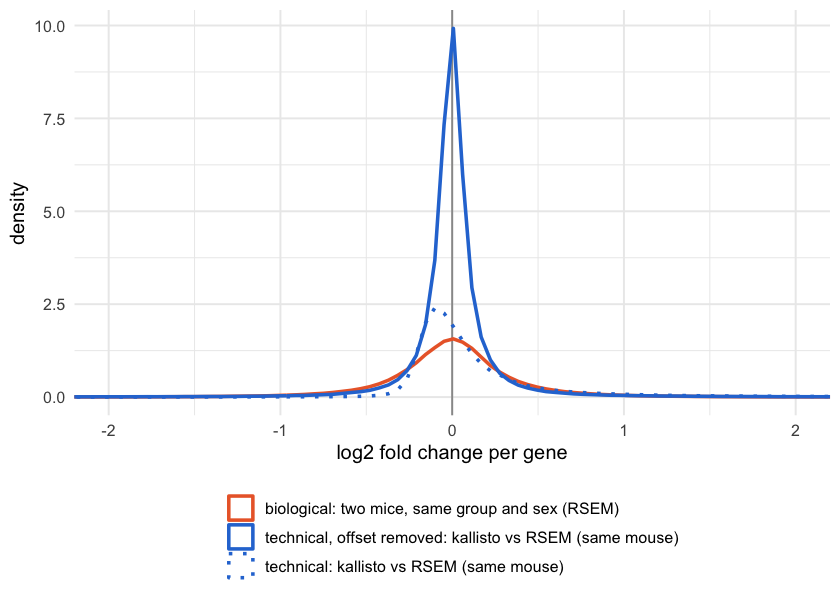

In [4]:
# SD per mouse (technical, offset removed) vs per pair of mice (biological, RSEM); the comparisons share mice, so p is indicative
sds <- split(v$per$sd, v$per$comparison)
tech <- sds[[grep('offset removed', names(sds))]]; bio <- sds[[grep('biological.*RSEM', names(sds))]]
cat(sprintf('SD technical %.2f-%.2f | biological %.2f-%.2f | Wilcoxon p = %.1g\n', min(tech), max(tech), min(bio), max(bio), wilcox.test(tech, bio)$p.value))
options(repr.plot.width = 7, repr.plot.height = 5)
tpm_variation_plot(v)

**Reading.** For a typical gene the methods differ less than two mice do. The exception is a tail of genes with a fixed method offset (mostly predicted genes `Gm…` and small RNAs such as Rn7s2), which makes the raw technical SD and the share of genes differing > 2-fold larger than the biological ones. With the offset removed, every mouse's technical SD is below every pair's biological SD, and the method changes a fold change between two mice much less than the mice differ (`pair log2FC`). This shows the methods agree; it does not show which is more accurate.

## 3 · Differential expression with each method
The four DESeq2 analyses of notebook 03, once per method: number of DEGs (padj < 0.05), up and down.

In [5]:
# the DESeq2 models (dds) and result tables (de) of notebook 03, for each method; then DEGs (padj < 0.05) up / down
counts <- list(kallisto = txi, RSEM = rsem)
dds <- lapply(counts, run_dds, samples = samples)
de <- lapply(dds, de_tables, genes = genes)
bind_rows(lapply(de, \(r) bind_rows(lapply(r, n_deg), .id = 'contrast')), .id = 'method')

method,contrast,up,down
<chr>,<chr>,<int>,<int>
kallisto,aging_18v3,101,25
kallisto,aging_21v3,82,52
kallisto,aDR,64,75
kallisto,YMP,17,24
RSEM,aging_18v3,95,20
RSEM,aging_21v3,74,42
RSEM,aDR,46,72
RSEM,YMP,22,28


**Agreement of the two methods** (a = kallisto, b = RSEM). `total_DEG_a` / `_b` = all DEGs of each method; the other columns use only genes tested by **both**: `shared` DEGs, `jaccard` (shared ÷ combined), `same_direction` (share of shared DEGs with the same sign), `lfc_spearman_all` / `_sig` (log2FC rank correlation over all genes / genes significant in either).

In [6]:
# agreement of the DE results of kallisto and RSEM, per comparison
pairs <- list(c('kallisto', 'RSEM'))
cmp <- method_agreement(de, pairs)
cmp

method_a,method_b,contrast,total_DEG_a,total_DEG_b,genes_tested_both,DEG_a,DEG_b,shared,jaccard,same_direction,lfc_spearman_all,lfc_spearman_sig
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
kallisto,RSEM,aging_18v3,126,115,15812,121,115,86,0.57,1,0.839,0.903
kallisto,RSEM,aging_21v3,134,116,16725,128,116,89,0.57,1,0.824,0.964
kallisto,RSEM,aDR,139,118,12913,128,117,84,0.52,1,0.887,0.954
kallisto,RSEM,YMP,41,50,17097,40,48,25,0.40,1,0.851,0.916


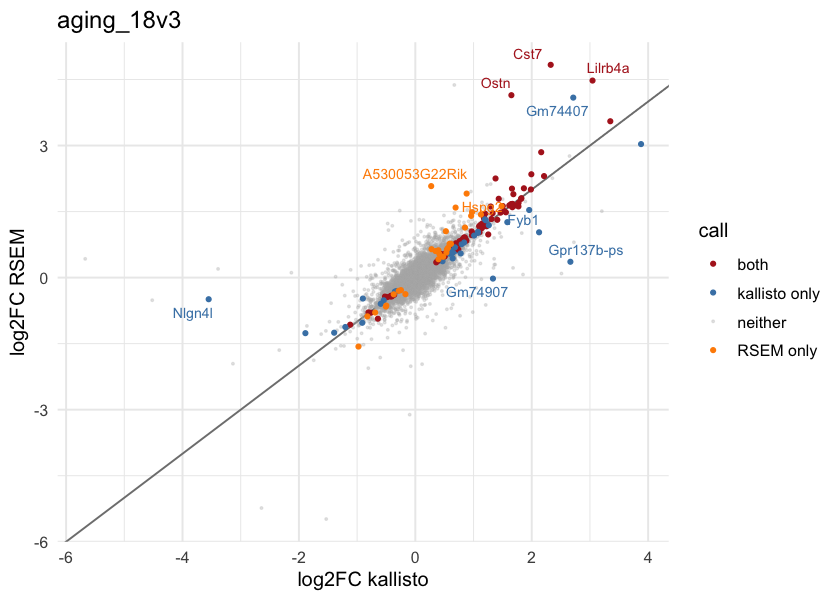

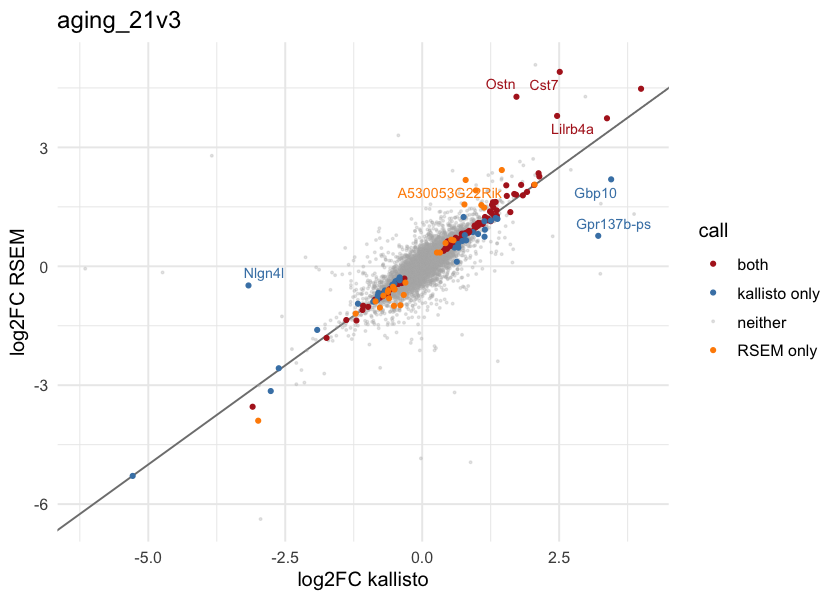

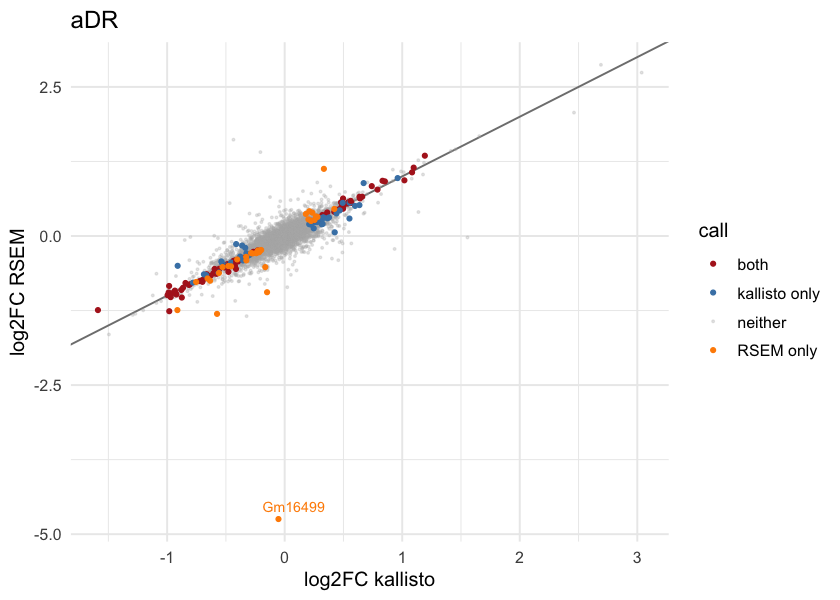

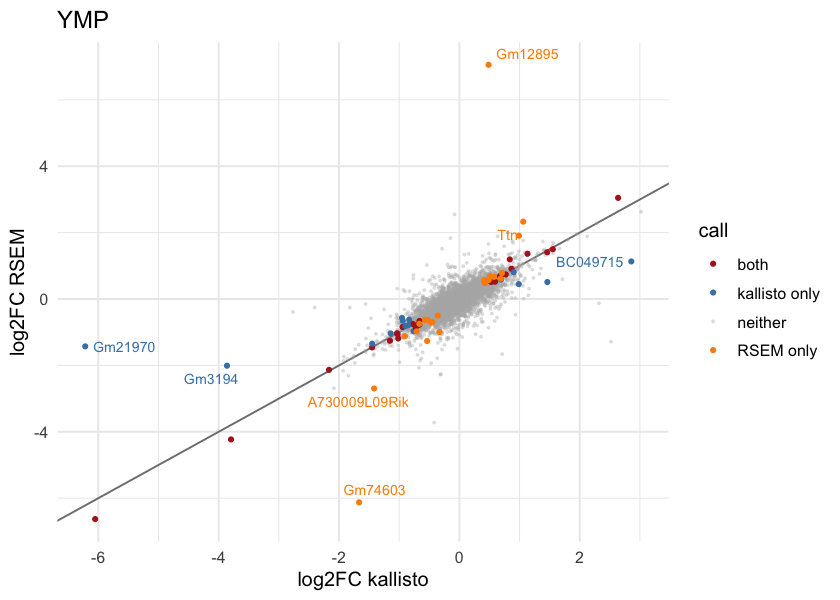

In [7]:
# log2FC per gene, kallisto (x) against RSEM (y); colour = which method calls the gene a DEG
for (n in names(de$kallisto)) print(lfc_scatter(de$kallisto[[n]], de$RSEM[[n]], n, names = c('kallisto', 'RSEM')))

**Where they disagree.** Genes called by only kallisto (`first only`) or only RSEM (`second only`), with their typical expression (`median_baseMean`, average normalised count). They are not consistently weaker expressed than the genes both methods call (lower in some comparisons, similar or higher in others), so the disagreements are not only low-count noise.

In [8]:
# per comparison: number of DEGs called by both / only kallisto / only RSEM, and their median expression
single_method_calls(de, pairs)

first,second,contrast,call,n_genes,median_baseMean
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>
kallisto,RSEM,aging_18v3,both,86,102
kallisto,RSEM,aging_18v3,first only,35,84
kallisto,RSEM,aging_18v3,second only,29,150
kallisto,RSEM,aging_21v3,both,89,175
kallisto,RSEM,aging_21v3,first only,39,106
kallisto,RSEM,aging_21v3,second only,27,263
kallisto,RSEM,aDR,both,84,473
kallisto,RSEM,aDR,first only,44,466
kallisto,RSEM,aDR,second only,33,573


## 4 · Properties of each method
One row per method, measured the same way for both ([criteria](../docs/pipeline.md#choosing-the-counting-method)). Saved as `results/compare/method_evidence.csv`.

| Column | Meaning | Better |
|---|---|---|
| `counted_pairs_pct_median`, `min`, `max` | share of trimmed read pairs counted in a gene | higher (more data used) |
| `genes_detected` | genes with ≥ 10 counts in ≥ 3 samples | not decisive |
| `replicate_r_median` | correlation between mice of the same group | higher |
| `dispersion_*` | median DESeq2 dispersion per analysis (noise between mice) | lower |
| `DEG_without`, `DEG_with`, `jaccard_outlier` | aging DEGs (21 vs 3 months) without / with SRR21355389, and their overlap | higher overlap |
| `aging_genes_up_of_5`, `aDR_genes_up_of_23` | genes the paper reports as up, found up (sanity check) | all up |

In [9]:
# one row per method: the measurements described in the table above
evidence <- method_evidence(counts, dds, de, samples, genes, ids)
evidence

method,counted_pairs_pct_median,min,max,genes_detected,replicate_r_median,dispersion_aging,dispersion_aDR,dispersion_YMP,DEG_without,DEG_with,jaccard_outlier,aging_genes_up_of_5,aDR_genes_up_of_23
<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>,<int>
RSEM,54.8,47.2,60.1,19311,0.9861,0.023,0.018,0.020,114,239,0.43,5,19
kallisto,68.8,65.1,72.5,26273,0.9864,0.020,0.015,0.018,132,279,0.42,5,19


## 5 · Save

In [10]:
# summary tables (in git); per-gene DE tables of RSEM (not in git)
dir.create(file.path(ROOT, 'results/compare'), showWarnings = FALSE)
write_csv(per_sample, file.path(ROOT, 'results/compare/counts_per_sample.csv'))
write_csv(var_tab, file.path(ROOT, 'results/compare/tpm_variation.csv'))
write_csv(cmp, file.path(ROOT, 'results/compare/de_agreement.csv'))
write_csv(evidence, file.path(ROOT, 'results/compare/method_evidence.csv'))
imap(de$RSEM, \(r, n) write_csv(r, file.path(ROOT, 'results/compare', paste0('rsem_', n, '.csv')))) %>% invisible()
list.files(file.path(ROOT, 'results/compare'))

[1] "counts_per_sample.csv" "de_agreement.csv"      "method_evidence.csv"  
[4] "rsem_aDR.csv"          "rsem_aging_18v3.csv"   "rsem_aging_21v3.csv"  
[7] "rsem_YMP.csv"          "tpm_variation.csv"